# k-Nearest Neighbours (kNN)

**Agenda**

1. Where kNN fits
2. The kNN algorithm - for classification and for regression
3. Why scaling matters
4. Choosing k
5. Evaluating a classifier: the confusion matrix, precision, recall, F1
6. kNN vs linear and logistic regression: parametric vs nonparametric models, nonlinear data
7. The curse of dimensionality
8. Pros and cons
9. Summary
10. Homework: kNN on the Iris dataset

## Setup: imports and helper code

The helpers generate the toy datasets and draw the figures. You do not need to understand the
helper code.

In [1]:
# The imports used in the rest of the notebook
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# Helper code that can be skipped

def make_wavy(n, rng, flip=0.15):
    # 2 features; class 1 above a wavy line, class 0 below it; 15% of the labels flipped (noise)
    X = np.c_[rng.uniform(0, 6, n), rng.uniform(-2, 2, n)]
    y = (X[:, 1] > np.sin(1.3 * X[:, 0])).astype(int)
    noisy = rng.random(n) < flip
    y[noisy] = 1 - y[noisy]
    return X, y


def make_circles(n, rng):
    # class 0 on a small circle, class 1 on a bigger circle around it
    radius = np.r_[rng.normal(1.0, 0.25, n), rng.normal(2.5, 0.35, n)]
    angle = rng.uniform(0, 2 * np.pi, 2 * n)
    return np.c_[radius * np.cos(angle), radius * np.sin(angle)], np.r_[np.zeros(n, int), np.ones(n, int)]


def knn_vote_fraction(X_train, y_train, X_query, k):
    # for every query point: the fraction of its k nearest training points that are class 1 (all queries at once)
    squared = ((X_query[:, None, :] - X_train[None, :, :]) ** 2).sum(axis=2)
    nearest = np.argsort(squared, axis=1)[:, :k]
    return y_train[nearest].mean(axis=1)


def draw_classes(ax, X, y, size=30):
    ax.scatter(*X[y == 0].T, c="#c62828", marker="o", s=size, label="class 0", edgecolors="white", linewidths=0.5)
    ax.scatter(*X[y == 1].T, c="#1f4e79", marker="s", s=size, label="class 1", edgecolors="white", linewidths=0.5)


def draw_vote_map(ax, predict_fraction, X, y, title=""):
    # background: the predicted fraction of class 1 votes; black line: where it is 0.5 (the decision boundary)
    x1, x2 = np.meshgrid(np.linspace(X[:, 0].min() - 0.3, X[:, 0].max() + 0.3, 150),
                         np.linspace(X[:, 1].min() - 0.3, X[:, 1].max() + 0.3, 150))
    fraction = predict_fraction(np.c_[x1.ravel(), x2.ravel()]).reshape(x1.shape)
    ax.contourf(x1, x2, fraction, levels=np.linspace(0, 1, 11), cmap="RdBu", alpha=0.35)
    ax.contour(x1, x2, fraction, levels=[0.5], colors="black", linewidths=1.5)
    draw_classes(ax, X, y, size=18)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])


def draw_query_example():
    rng = np.random.default_rng(3)
    X, y = make_wavy(30, rng, flip=0)
    queries = np.array([[1.2, 0.1], [2.3, -1.1]])
    fig, ax = plt.subplots(figsize=(9, 4.5))
    draw_classes(ax, X, y, size=60)
    for query in queries:
        distances = np.sqrt(((X - query) ** 2).sum(axis=1))
        nearest = np.argsort(distances)[:3]
        for i in nearest:
            ax.plot(*zip(query, X[i]), color="black", lw=1, zorder=1)
        predicted = int(y[nearest].mean() > 0.5)
        ax.scatter(*query, marker="*", s=400, c=["#c62828", "#1f4e79"][predicted], edgecolors="black", zorder=3)
    ax.set_title("k = 3: the stars are new points, the lines go to their 3 nearest neighbours")
    ax.legend(loc="upper right")
    plt.close(fig)
    return fig


def draw_knn_boundaries(X, y, ks):
    fig, axes = plt.subplots(1, len(ks), figsize=(5 * len(ks), 3.8))
    for ax, k in zip(axes, ks):
        draw_vote_map(ax, lambda Q, k=k: knn_vote_fraction(X, y, Q, k), X, y, title=f"k = {k}")
    fig.tight_layout()
    plt.close(fig)
    return fig


def draw_error_vs_k(ks, train_errors, val_errors):
    best = ks[int(np.argmin(val_errors))]
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(ks, train_errors, "o-", color="#4f81bd", label="training error")
    ax.plot(ks, val_errors, "o-", color="#f79646", label="validation error")
    ax.axvline(best, color="gray", linestyle="--")
    ax.text(best, max(val_errors), f" best k = {best}", va="top")
    ax.set_xscale("log")
    ax.set_xticks(ks, [str(k) for k in ks])
    ax.set_xlabel("k (log scale)  -  small k: complex model, large k: simple model")
    ax.set_ylabel("error rate (1 - accuracy)")
    ax.text(1.1, 0.02, "overfitting\n(high variance)", color="#c62828")
    ax.text(ks[-2], 0.02, "underfitting\n(high bias)", color="#c62828", ha="right")
    ax.legend(loc="center right")
    plt.close(fig)
    return fig


def draw_confusion_matrix(y_true, y_pred, title=""):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    cells = [[(tp, "true positives (TP)", "#a5d6a7"), (fn, "false negatives (FN)", "#ffcc80")],
             [(fp, "false positives (FP)", "#ffcc80"), (tn, "true negatives (TN)", "#a5d6a7")]]
    fig, ax = plt.subplots(figsize=(5.5, 3.8))
    for row in range(2):
        for col in range(2):
            count, name, colour = cells[row][col]
            ax.add_patch(plt.Rectangle((col, 1 - row), 1, 1, facecolor=colour, edgecolor="white", lw=3))
            ax.text(col + 0.5, 1.6 - row, str(count), ha="center", fontsize=18, fontweight="bold")
            ax.text(col + 0.5, 1.3 - row, name, ha="center", fontsize=9)
    ax.set_xticks([0.5, 1.5], ["predicted 1", "predicted 0"])
    ax.set_yticks([1.5, 0.5], ["actual 1", "actual 0"])
    ax.set_xlim(0, 2)
    ax.set_ylim(0, 2)
    ax.tick_params(length=0)
    ax.set_title(title)
    plt.close(fig)
    return fig, (tp, fn, fp, tn)


def fit_logistic_regression(X, y, learning_rate=0.5, n_iters=2000):
    # logistic regression from the last lecture
    weights, bias = np.zeros(X.shape[1]), 0.0
    for _ in range(n_iters):
        y_prob = 1 / (1 + np.exp(-(X @ weights + bias)))
        weights = weights + learning_rate * X.T @ (y - y_prob) / len(y)
        bias = bias + learning_rate * np.mean(y - y_prob)
    return lambda Q: 1 / (1 + np.exp(-(Q @ weights + bias)))


def draw_nonlinear_comparison():
    rng = np.random.default_rng(0)
    X_train, y_train = make_circles(150, rng)
    X_test, y_test = make_circles(150, rng)
    predict_logistic = fit_logistic_regression(X_train, y_train)
    predict_knn = lambda Q: knn_vote_fraction(X_train, y_train, Q, 7)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
    for ax, name, predict in zip(axes, ("logistic regression", "kNN, k = 7"), (predict_logistic, predict_knn)):
        test_accuracy = np.mean((predict(X_test) > 0.5) == y_test)
        draw_vote_map(ax, predict, X_train, y_train, f"{name}: test accuracy {test_accuracy:.0%}")
    fig.tight_layout()
    plt.close(fig)
    return fig


def draw_regression_comparison():
    rng = np.random.default_rng(1)
    x = rng.uniform(0, 1, 60)
    y = np.sin(2 * np.pi * x) + rng.normal(0, 0.25, 60)
    grid = np.linspace(0, 1, 400)
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.scatter(x, y, color="#4f81bd", zorder=3, label="training points")
    slope, intercept = np.polyfit(x, y, 1)
    ax.plot(grid, slope * grid + intercept, color="gray", lw=2, label="linear regression")
    for k, colour in ((1, "#ef9a9a"), (7, "#c62828"), (40, "#6a1b9a")):
        nearest = np.argsort(np.abs(grid[:, None] - x[None, :]), axis=1)[:, :k]
        ax.plot(grid, y[nearest].mean(axis=1), color=colour, lw=2, label=f"kNN regression, k = {k}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend(loc="lower left", fontsize=9)
    ax.set_title("Regression on a wave: the average of the k nearest training values")
    plt.close(fig)
    return fig


def draw_distance_concentration():
    rng = np.random.default_rng(42)
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), sharey=True)
    for ax, dims in zip(axes, (2, 10, 100, 1000)):
        points = rng.uniform(0, 1, (200, dims))
        gram = points @ points.T
        squared = np.diag(gram)[:, None] + np.diag(gram)[None, :] - 2 * gram
        distances = np.sqrt(np.maximum(squared, 0))[np.triu_indices(200, 1)]
        distances = distances / distances.mean()
        ax.hist(distances, bins=40, range=(0, 2.5), color="#4f81bd")
        ax.set_title(f"{dims} dimensions\nclosest {distances.min():.2f}, farthest {distances.max():.2f}")
        ax.set_xlabel("distance / mean distance")
    axes[0].set_ylabel("number of pairs")
    fig.tight_layout()
    plt.close(fig)
    return fig


def draw_irrelevant_features():
    rng = np.random.default_rng(1)
    X_train, y_train = make_wavy(400, rng, flip=0)
    X_test, y_test = make_wavy(400, rng, flip=0)
    counts, accuracies = (0, 2, 5, 10, 20, 50, 100), []
    for extra in counts:
        # the 2 real features scaled to [0, 1], plus `extra` random features that have nothing to do with the class
        train = np.c_[X_train / [6, 4], rng.uniform(0, 1, (400, extra))]
        test = np.c_[X_test / [6, 4], rng.uniform(0, 1, (400, extra))]
        accuracies.append(np.mean((knn_vote_fraction(train, y_train, test, 5) > 0.5) == y_test))
    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.plot(counts, accuracies, "o-", color="#c62828")
    ax.axhline(max(np.mean(y_test), 1 - np.mean(y_test)), color="gray", linestyle="--")
    ax.text(counts[-1], max(np.mean(y_test), 1 - np.mean(y_test)), "always guessing the bigger class",
            ha="right", va="bottom", color="gray")
    ax.set_xlabel("number of irrelevant (random) features added to the 2 real ones")
    ax.set_ylabel("test accuracy (k = 5)")
    ax.set_ylim(0.4, 1.0)
    plt.close(fig)
    return fig

---

# 1. Where kNN (k Nearest Neighbours) fits

The same weather data can be used for all three kinds of machine learning from the last lecture. The features are
the humidity (%), the wind (km/h) and the rain (mm) of a day:

| Humidity (%) | Wind (km/h) | Rain (mm) | Temperature class | Temperature (°C) |
|---|---|---|---|---|
| 80 | 15 | 2.0 | Mild | 22 |
| 50 | 5 | 0.0 | Hot | 30 |
| 85 | 20 | 5.5 | Cold | 18 |
| 60 | 10 | 0.0 | Mild | 25 |
| 90 | 25 | 8.0 | Cold | 10 |

A new day: $x_t = (\text{humidity} = 85, \text{wind} = 25, \text{rain} = 6.0)$.

- **Classification**: predict the temperature **class** of $x_t$, $y \in \{\text{Cold}, \text{Mild}, \text{Hot}\}$.
- **Regression**: predict the **temperature** of $x_t$, $y \in \mathbb{R}$.

**kNN is a supervised learning algorithm - it can do both classification and regression.** And it does them in a way
that is very different from linear and logistic regression.

---

# 2. The kNN algorithm

## 2.1 The idea

The idea is to create the prediction of point $x$ based on the closest to $x$ points in the training dataset. To predict the label of a new example:

1. Compute the **distance** from the new example to **every** training example.
2. Take the **k** training examples with the smallest distances (the **k nearest neighbours**).
3. Combine their labels:
    - **classification**: the **majority vote** - the most common class among the k neighbours
    - **regression**: the **mean (average)** of the k neighbours' values

Every example is a point in an $n$-dimensional space (one dimension per feature), and "near" means a small distance
in that space. We can define distance in many different ways, but usually we use the **Euclidean distance**, which is the length of the straight line between two points $x (x_1, \cdots, x_n)$ and $x' (x'_1, \cdots, x'_n)$:

$$d(x, x') = \sqrt{(x_1 - x'_1)^2 + (x_2 - x'_2)^2 + \dots + (x_n - x'_n)^2}$$

Other metrics exist, e.g. the **Manhattan distance** $\sum_i |x_i - x'_i|$ (the sum of the absolute differences). The metric is a hyperparameter of kNN, just like $k$.

> IMPORTANT: There is **no training**. Fitting kNN just means storing the training data. All the work happens when we predict.

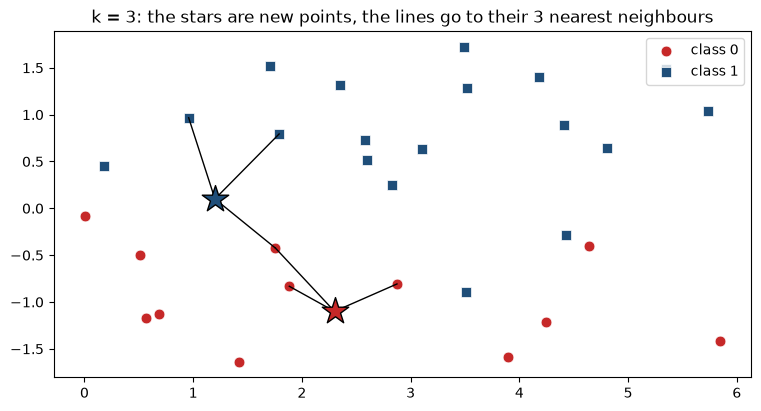

In [3]:
draw_query_example()

In the image above, the two stars are the new points we are trying to classify. The first point's 3 closest neighbours are 2 blue points and 1 red point. Since there are more blue neighbours than red neighbours, we predict this point will be blue. For the second star, all three closest neighbours are red, so we predict this point is red.

## 2.2 The code

The whole algorithm, for one new example `x`:

In [4]:
def euclidean_distance(a, b):
    return np.sqrt(np.sum((a - b) ** 2, axis=-1))


def k_nearest(X_train, x, k):
    distances = euclidean_distance(X_train, x)            # 1. the distance to every training example
    return np.argsort(distances)[:k]                       # 2. the indices of the k smallest distances


def knn_classify(X_train, y_train, x, k):
    labels, votes = np.unique(y_train[k_nearest(X_train, x, k)], return_counts=True)
    return labels[np.argmax(votes)]                        # 3. the majority vote


def knn_regress(X_train, y_train, x, k):
    return np.mean(y_train[k_nearest(X_train, x, k)])     # 3. the mean of the neighbours' values

Now the weather example. The new day is $x_t = (85, 25, 6.0)$:

In [5]:
weather_X = np.array([[80, 15, 2.0], [50, 5, 0.0], [85, 20, 5.5], [60, 10, 0.0], [90, 25, 8.0]])
weather_class = np.array(["Mild", "Hot", "Cold", "Mild", "Cold"])
weather_temperature = np.array([22, 30, 18, 25, 10])
new_day = np.array([85, 25, 6.0])

for _i, _distance in enumerate(euclidean_distance(weather_X, new_day)):
    print(f"day {_i + 1}: distance {_distance:5.2f}, {weather_class[_i]}, {weather_temperature[_i]} °C")
print()
for _k in (1, 3):
    print(f"k = {_k}: neighbours {(k_nearest(weather_X, new_day, _k) + 1).tolist()} -> "
          f"class {knn_classify(weather_X, weather_class, new_day, _k)}, "
          f"temperature {knn_regress(weather_X, weather_temperature, new_day, _k):.1f} °C")

day 1: distance 11.87, Mild, 22 °C
day 2: distance 40.76, Hot, 30 °C
day 3: distance  5.02, Cold, 18 °C
day 4: distance 29.77, Mild, 25 °C
day 5: distance  5.39, Cold, 10 °C

k = 1: neighbours [3] -> class Cold, temperature 18.0 °C
k = 3: neighbours [3, 5, 1] -> class Cold, temperature 16.7 °C


- With **k = 1** the only neighbour is day 3 (distance 5.02): the class is **Cold**, the temperature **18 °C**.
- With **k = 3** the neighbours are days 3, 5 and 1: the votes are Cold, Cold, Mild → **Cold**; the temperature is the
  mean $\frac{18 + 10 + 22}{3} = 16.7$ °C.

The **same algorithm** does classification and regression. And it has no problem with
**three** classes, the majority vote works for any number of classes.

---

# 3. Scaling is mandatory

The distance adds up the differences of **all** features. If one feature is measured on a much bigger scale, it dominates the distance on its own. In the weather data, humidity varies by up to 40 (50 to 90) and rain by up to 8.

An extreme example: predict whether a person buys a product, when only the **age** matters, but there is also an irrelevant **income** feature in €:

In [6]:
_rng = np.random.default_rng(2)
_age = _rng.uniform(18, 70, 400)
_income = _rng.uniform(20_000, 100_000, 400)           # irrelevant, but in much bigger numbers
_buys = (_age < 35).astype(int)                          # only the age decides
_X = np.c_[_age, _income]
_train, _test = np.arange(300), np.arange(300, 400)


def _test_accuracy(X):
    predicted = knn_vote_fraction(X[_train], _buys[_train], X[_test], 5) > 0.5
    return np.mean(predicted == _buys[_test])


_mean, _std = _X[_train].mean(axis=0), _X[_train].std(axis=0)   # computed on the training set only
print(f"without scaling: test accuracy {_test_accuracy(_X):.0%}")
print(f"standardized:    test accuracy {_test_accuracy((_X - _mean) / _std):.0%}")

without scaling: test accuracy 52%
standardized:    test accuracy 99%


Without scaling, a difference of 30 years in age is nothing next to a difference of 1,000 € in income, so the
"nearest" neighbours are just the people with a similar income - and the prediction is close to a guess. After
**standardization** (from the last lecture: subtract the mean, divide by the standard deviation - computed on the
training set only), both features count equally, and kNN finds the right neighbours.

> **Always scale the features before kNN.** Linear and logistic regression can (in theory) compensate for different
> scales with their weights; kNN has no weights - every feature counts exactly as much as its numbers say.

---

# 4. Choosing k

## 4.1 The effect of k

The data below has two features and two classes separated by a **wavy** line, and 15% of the labels are deliberately flipped, to simulate **noise, which is almost always present in real data**. The black line is the decision boundary:

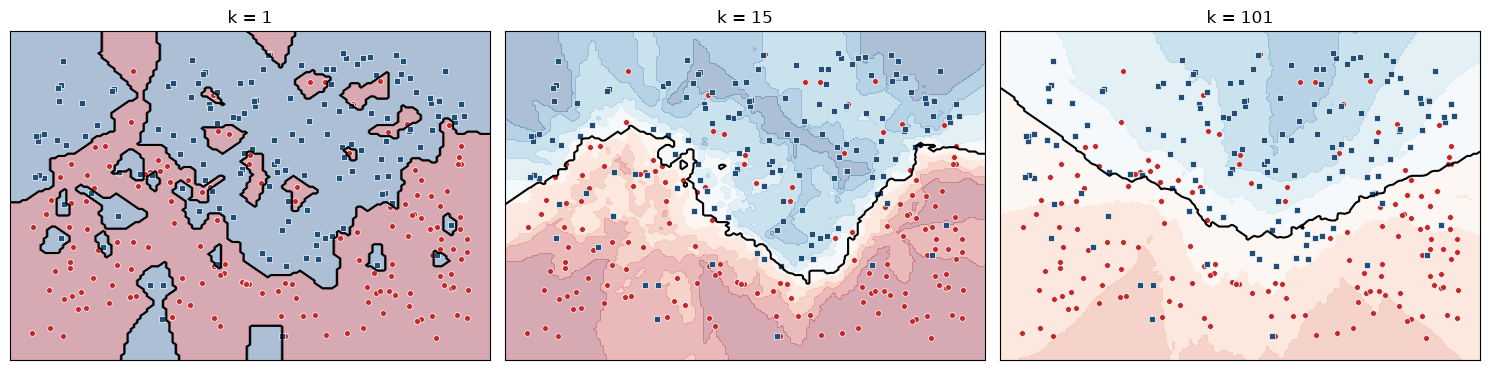

In [7]:
_rng = np.random.default_rng(0)
wavy_X_train, wavy_y_train = make_wavy(300, _rng)
wavy_X_val, wavy_y_val = make_wavy(600, _rng)
draw_knn_boundaries(wavy_X_train, wavy_y_train, ks=(1, 15, 101))

- **k = 1**: every training point decides its own small area - even the noisy (wrongly labelled) points get their own "islands". The boundary is extremely complex. **This is an example of kNN overfitting (high variance) - a slightly different training set would give a completely different picture.**
- **k = 15**: the votes average out the noise, and the boundary follows the real wave.
- **k = 101**: every prediction averages a large part of the data, and the boundary becomes too smooth, and doesn't follow the bends of the wave as well. **This is an example of underfitting (high bias)**. In the extreme, when $k = $ all training points, kNN predicts the most common class for **every** input.

So **k controls the complexity of the model**: a small k is a complex model, a large k is a simple one.

## 4.2 Training error vs validation error

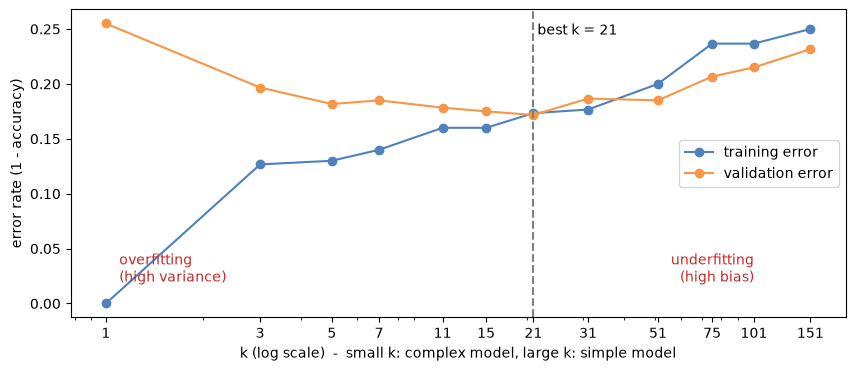

In [8]:
_ks = [1, 3, 5, 7, 11, 15, 21, 31, 51, 75, 101, 151]
_train_errors = [np.mean((knn_vote_fraction(wavy_X_train, wavy_y_train, wavy_X_train, k) > 0.5) != wavy_y_train)
                 for k in _ks]
_val_errors = [np.mean((knn_vote_fraction(wavy_X_train, wavy_y_train, wavy_X_val, k) > 0.5) != wavy_y_val)
               for k in _ks]
draw_error_vs_k(_ks, _train_errors, _val_errors)

- The **training error is 0 for k = 1**: every training point is its own nearest neighbour (distance 0), so it always
  "predicts" its own label. A perfect training score here says nothing about generalization - a typical sign of
  overfitting. As k grows, the training error grows.
- The **validation error** has the familiar U-shape from the last lecture: high for k = 1 (overfitting), lowest in the middle, rising again for large k (underfitting).
- Even the best k has about 17% error, since the 15% of flipped labels cannot be predicted by any model.

## 4.3 How to choose the hyperparameters properly

- k is a **hyperparameter**: choose it on a **validation set** or with **cross-validation** on the training set - never on the test set. Plotting the error for many k and picking the bottom on the **test** set is a common mistake, because the test set was used to make a decision (**data
  leakage**).
- The **scaling** must be part of every cross-validation round: compute the mean and standard deviation on the training folds only, then apply them to the validation fold.
- For **two classes**, search only over **odd** k, to avoid tied votes.

---

# 5. Evaluating a classifier

So far we measured classifiers with **accuracy**. It is not always enough - let us look closer at the predictions of kNN
with the best k from the previous section on the validation set. Class 1 is the **positive** class (e.g. "cancer present"), class 0 the **negative** one.

## 5.1 The confusion matrix

A table of all four combinations of the true class and the predicted class:

- **True positive (TP)**: actually 1, predicted 1 - a correct alarm
- **False negative (FN)**: actually 1, predicted 0 - a **missed** case
- **False positive (FP)**: actually 0, predicted 1 - a **false alarm**
- **True negative (TN)**: actually 0, predicted 0 - correctly left alone

accuracy  = (TP + TN) / all  = (219 + 278) / 600 = 0.828
precision = TP / (TP + FP)   = 219 / 265 = 0.826
recall    = TP / (TP + FN)   = 219 / 276 = 0.793
F1        = 2PR / (P + R)    = 0.810


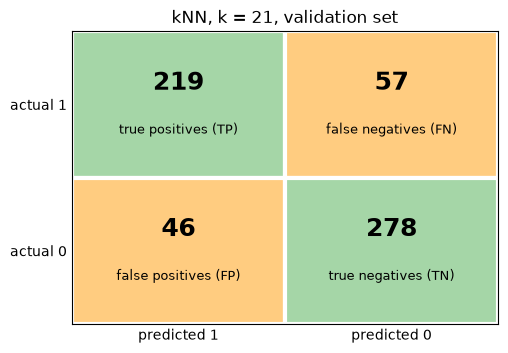

In [9]:
_predicted = (knn_vote_fraction(wavy_X_train, wavy_y_train, wavy_X_val, 21) > 0.5).astype(int)
_figure, (_tp, _fn, _fp, _tn) = draw_confusion_matrix(wavy_y_val, _predicted, "kNN, k = 21, validation set")
_precision, _recall = _tp / (_tp + _fp), _tp / (_tp + _fn)
print(f"accuracy  = (TP + TN) / all  = ({_tp} + {_tn}) / {_tp + _tn + _fp + _fn} = {(_tp + _tn) / (_tp + _tn + _fp + _fn):.3f}")
print(f"precision = TP / (TP + FP)   = {_tp} / {_tp + _fp} = {_precision:.3f}")
print(f"recall    = TP / (TP + FN)   = {_tp} / {_tp + _fn} = {_recall:.3f}")
print(f"F1        = 2PR / (P + R)    = {2 * _precision * _recall / (_precision + _recall):.3f}")
_figure

**In the ideal case, the values on the main diagonal are big, and the other values are small.**

## 5.2 Accuracy, precision, recall, F1

| Metric | Formula | Question it answers |
|---|---|---|
| **Accuracy** | $\frac{TP + TN}{TP + TN + FP + FN}$ | what fraction of **all** predictions is correct? |
| **Precision** | $\frac{TP}{TP + FP}$ | of everything we **predicted** positive, how much really is positive? |
| **Recall** | $\frac{TP}{TP + FN}$ | of everything that **really is** positive, how much did we find? |
| **F1 score** | $\frac{2 \cdot P \cdot R}{P + R}$ | one number that combines precision and recall (their harmonic mean) |

Think of a search engine, like Google:
- **precision** - how many of the returned pages were useful?
- **recall** - were there useful pages that were not returned?

**Why accuracy is not enough**: 1,000 patients, 10 of them sick. A "model" that always says "healthy" has accuracy
$\frac{990}{1000} = 99\%$ - and finds **none** of the sick patients (recall = 0). With **imbalanced classes**, accuracy
hides exactly the mistakes we care about.

**Which metric matters more depends on the cost of each mistake**:

- cancer screening: a missed patient (FN) is much worse than a false alarm (FP) → maximize **recall**
- a spam filter: an important email in the spam folder (FP) is worse than one spam in the inbox (FN) → maximize **precision**

---

# 6. kNN vs linear and logistic regression

## 6.1 Parametric vs nonparametric models

- A **parametric** model has a **fixed number of parameters**, decided **before** seeing the data. Linear regression with one feature has 2 parameters ($w_0$, $w_1$) - whether we train it on 10 houses or on 10 million. The parameters encode everything the model learned during training, after training the data can be thrown away. **Parametric methods always make an assumption about the shape of the function we are trying to approximate.**
- A **nonparametric** model makes **no fixed assumption about the shape** of the function. kNN has **no learned parameters at all** - the model **is** the training data. More data means a bigger, more detailed model, which is not always the case with parametric models.

| | Parameters | Hyperparameters |
|---|---|---|
| **Set by** | learned from the training data | chosen by us, or tuned (validation, cross-validation) |
| **Linear / logistic regression** | the weights $w$, the bias $b$ | the learning rate, the number of iterations |
| **kNN** | none - it stores the data | $k$, the distance metric |

"Nonparametric" does not mean "no hyperparameters" - kNN still has $k$ and the metric.

## 6.2 Nonlinear data

Linear and logistic regression assume a shape that is a straight line. kNN assumes nothing about the shape, its boundary goes wherever the data points are.

One class inside a ring of the other class:

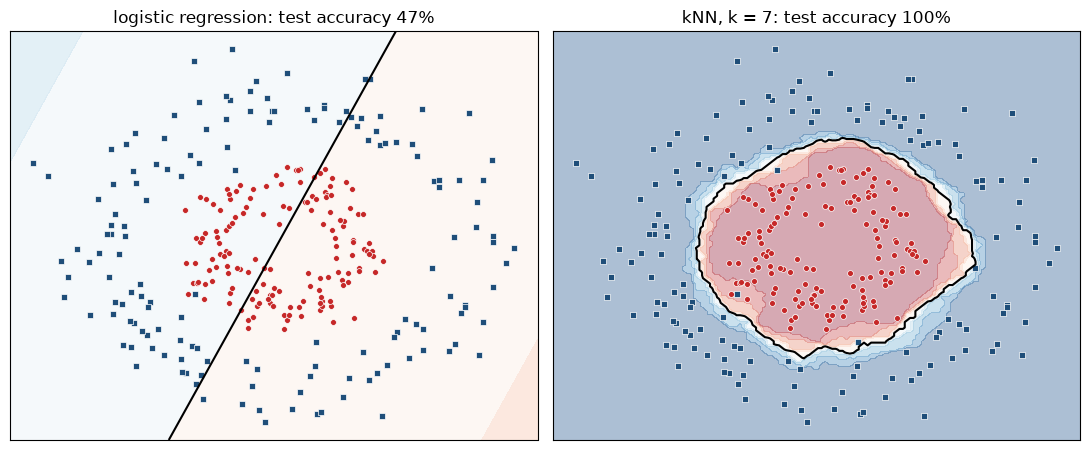

In [10]:
draw_nonlinear_comparison()

No straight line can separate a circle from the ring around it - logistic regression is no better than a coin flip. kNN
simply asks "what are the points around me?", and draws a round boundary on its own.

The same holds for **regression**. kNN regression predicts the **mean of the k nearest training values** - a step
function that follows the data:

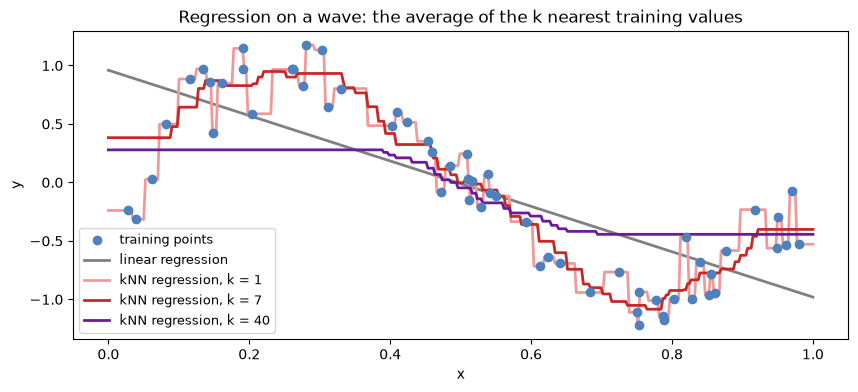

In [11]:
draw_regression_comparison()

- **Linear regression** (gray) is a straight line - it cannot follow a wave, however much data it gets (high bias).
- **kNN, k = 1** jumps to every single training value, noise included (overfitting).
- **kNN, k = 7** follows the wave and smooths out the noise.
- **kNN, k = 40** averages two thirds of all the points - almost flat (underfitting).

Note also that kNN regression can never predict outside the range of the training values - it only averages them. A
linear model can **extrapolate** (continue its line beyond the data), but kNN can't do this.

## 6.3 Side by side

| | Linear regression | Logistic regression | kNN |
|---|---|---|---|
| **Task** | regression | classification | both |
| **Parametric?** | yes - $n + 1$ weights | yes - $n + 1$ weights | no - stores all the data |
| **Training** | gradient descent | gradient descent | none - store the data |
| **Prediction** | fast: $n$ multiplications | fast: $n$ multiplications + sigmoid | slow: a distance to **every** training point |
| **Shape of the function / boundary** | a straight line / plane | a straight boundary | any shape |
| **Feature scaling** | helps gradient descent | helps gradient descent | essential |
| **Interpretable?** | yes - the weights say how much each feature matters | yes - the weights | only "these were the most similar examples" |
| **Main hyperparameters** | learning rate, iterations | learning rate, iterations | $k$, the distance metric |

---

# 7. The curse of dimensionality

kNN works well in 2 dimensions. Real data often has hundreds or thousands of features (the pixels of an image,
the words of a text). In high dimensions, distances behave strangely - this is called the **curse of dimensionality**.

## 7.1 The space becomes empty

As the number of features grows, a fixed-size training set covers a smaller and smaller part of the space of possible
examples. Even with only **binary** features, the number of possible examples grows exponentially: with 100 binary
features there are $2^{100} \approx 10^{30}$ possible examples, so even a training set of $10^{12}$ (a trillion) examples
covers only about $10^{-18}$ of the space.

## 7.2 All distances become the same

200 random points in a cube, and all the distances between pairs of them (divided by their mean, so different
dimensions can be compared):

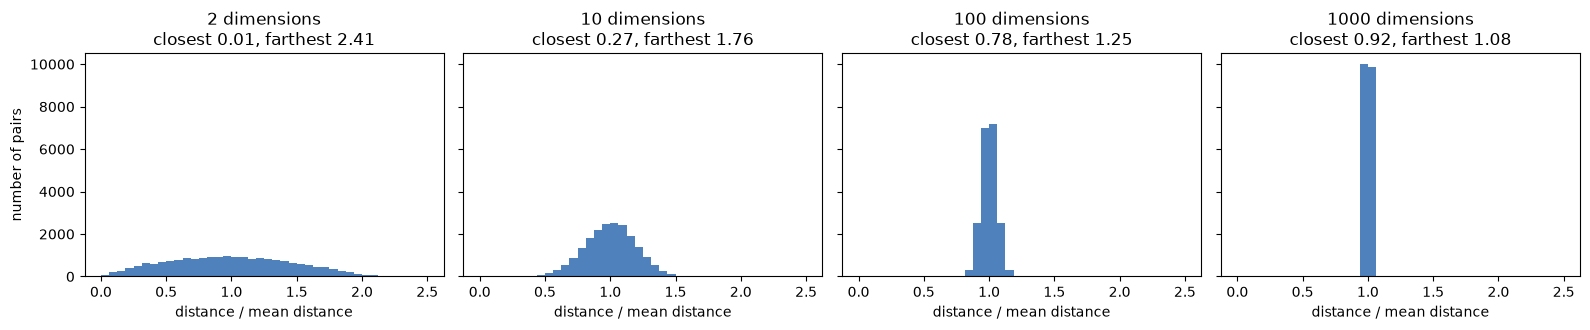

In [12]:
draw_distance_concentration()

In 2 dimensions, the distances range from almost 0 to 2.4 times the mean. In 1000 dimensions, **every** pair of points is
at almost the same distance (0.92 to 1.08 times the mean) - the nearest and the farthest point are practically equally
far. "The nearest neighbour" loses its meaning.

## 7.3 Irrelevant features make the model worse

Every feature adds to the distance, **relevant or not**. Below, the class depends only on 2 features.
Then we add more and more features with random values, which have nothing to do with the class:

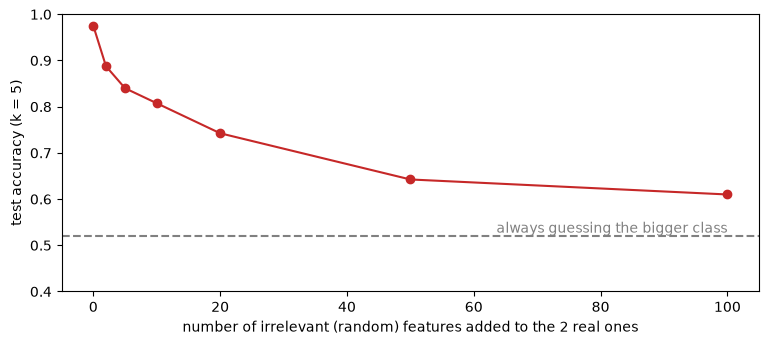

In [13]:
draw_irrelevant_features()

With 2 relevant features kNN is almost perfect. With 100 random features next to them, the random differences dominate
the distance, and the accuracy drops towards guessing.

**What helps**: fewer, better features (**feature selection**, or methods that combine many features into a few),
and more data. Models that **learn weights** (like linear and logistic regression) suffer less, because they can learn
to give an irrelevant feature a weight close to 0.

---

# 8. Pros and cons of kNN

| Pros | Cons |
|---|---|
| simple to understand and to implement | slow predictions - a distance to every training point |
| no training at all; new data is just added | needs to keep the **whole** training set in memory |
| works for classification **and** regression, and for any number of classes | the features **must** be scaled |
| any shape of decision boundary - handles nonlinear data | suffers from the **curse of dimensionality** and irrelevant features |
| robust to noisy labels when k is large enough (the votes average out the noise) | k and the distance metric must be chosen (cross-validation) |
| the prediction is easy to explain: "these are the most similar examples" | no model to inspect - it does not tell us which features matter |
| | with imbalanced classes, the bigger class tends to win the vote |

**When to use kNN**: a moderate amount of data, few (relevant) features, a complex boundary, and when a simple, strong
baseline is needed. Good examples: recommendation ("users similar to you liked..."), finding similar products,
images or documents, filling in missing values from similar examples.

---

# 9. Summary

| Concept | In one sentence |
|---|---|
| **kNN** | predict from the k most similar training examples: majority vote (classification) or mean (regression) |
| **Scaling** | without it, the feature with the biggest numbers decides alone |
| **k** | small k - complex model, overfitting; large k - simple model, underfitting; choose it by cross-validation |
| **Confusion matrix** | TP, FN, FP, TN - all four kinds of right and wrong predictions |
| **Precision / recall / F1** | how many alarms were real / how many real cases were found |
| **Nonparametric** | no fixed set of parameters; the model is the data and grows with it |
| **Curse of dimensionality** | in many dimensions all points are far apart and almost equally far - neighbours stop meaning anything |

---

# 10. Homework: kNN

## 10.1 Problem definition

Implement the **k-Nearest Neighbours** algorithm using the **Iris** dataset:
[archive.ics.uci.edu/ml/datasets/iris](https://archive.ics.uci.edu/ml/datasets/iris).

- To test the algorithm, apply **10-fold cross-validation**: divide the data randomly into 10 sets, and do 10 trainings
  and tests of the model, each time using one of the sets for testing and the other 9 for training.
- Display the **accuracy** for each of the 10 trainings, as well as their **arithmetic mean** (a summary assessment of
  the classifier).
- \* Optional: Make the algorithm accept the parameter **k** as input.
- \*\* Optional: Store the dataset in a **k-D tree**: https://www.youtube.com/watch?v=Glp7THUpGow.

## 10.2 The data

The Iris dataset has **150 flowers** of **3 species** (Iris setosa, Iris versicolor, Iris virginica), 50 of each. Every
flower has **4 features**, all in cm: the sepal length, the sepal width, the petal length and the petal width. The task
is **classification**: predict the species from the 4 measurements.

## 10.3 Tactics to try

- **"Training" kNN** means only storing the 9 training folds. The "test" is
  predicting every flower of the 10th fold, and comparing with its real species.
- **Shuffle before splitting**: in the file the flowers are sorted by species. Without shuffling, a fold could contain
  only one species, which is missing from the training folds. Ten folds of 15 flowers each; it is even better if every
  fold has 5 flowers of each species (**stratified** folds).
- **Scaling**: all four features are in cm, but their ranges differ (the petal width is 0.1 - 2.5 cm, the sepal length
  4.3 - 7.9 cm). Try the accuracy with and without standardization - and compute the mean and standard deviation on the
  9 training folds only.
- **Ties**: with 3 classes, even an odd k can give a tie (e.g. k = 3 with one vote for each species). Decide what to do -
  e.g. take the class of the nearest neighbour among the tied classes.
- **Choosing k**: here the 10-fold cross-validation **evaluates** the classifier for a fixed k. If you also use it to pick
  the best k, the mean accuracy of the best k is slightly optimistic - just like choosing k on the test set.
- **k-D tree**: build it recursively - split by the median of feature 0, then 1, 2, 3, then 0 again. For the search, keep
  the k best points found so far, and only visit the far side of a split if the distance from the query to the splitting
  line is smaller than the distance to the k-th best point.